In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# plt.style.use('gglot')
# sns.set(rc={'figure.figsize':(10,5)})

In [ ]:
import os
os.getcwd()

'/content'

In [ ]:
df = pd.read_csv("/content/airlines_flights_data.csv")

In [ ]:
df.head()

,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   index             300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


In [ ]:
df.describe()

,index,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


In [ ]:
df.shape

(300153, 12)

In [ ]:

df.isnull()

,index,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
300148,False,False,False,False,False,False,False,False,False,False,False,False
300149,False,False,False,False,False,False,False,False,False,False,False,False
300150,False,False,False,False,False,False,False,False,False,False,False,False
300151,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
print(df.columns)

Index(['index', 'airline', 'flight', 'source_city', 'departure_time', 'stops',
       'arrival_time', 'destination_city', 'class', 'duration', 'days_left',
       'price'],
      dtype='object')


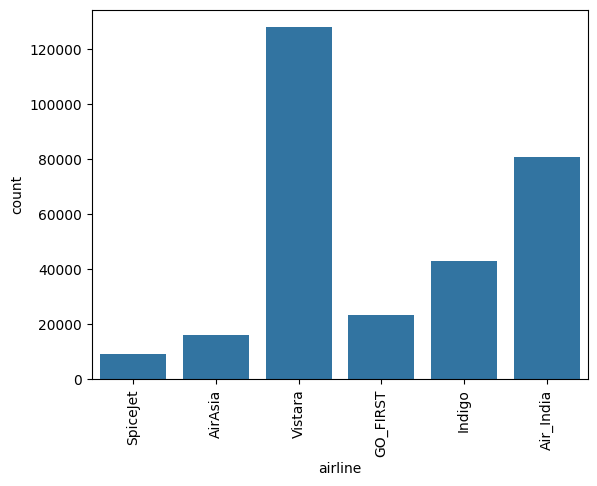

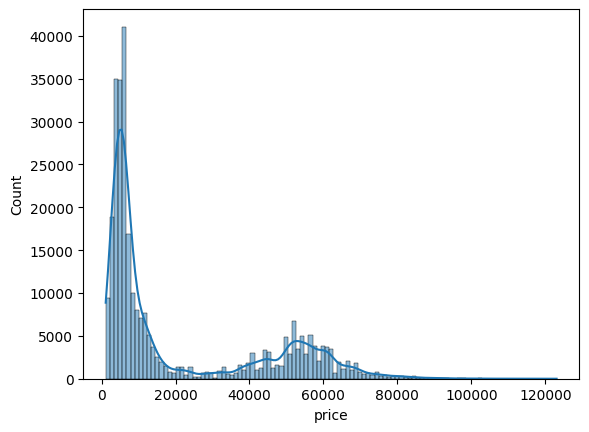

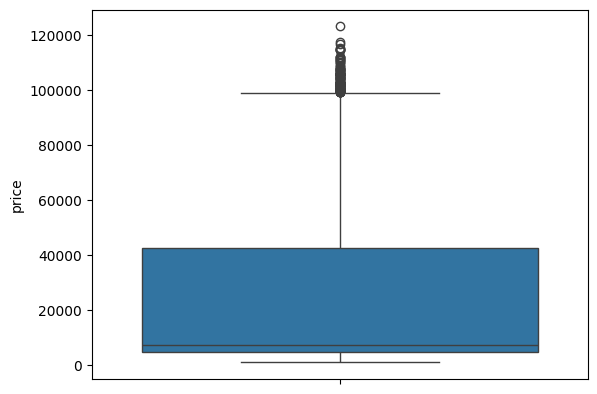

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Airline
sns.countplot(x='airline',data=df)
plt.xticks(rotation=90)
plt.show()

#Price distribution
sns.histplot(df['price'],kde=True)
plt.show()

#price boxplot
sns.boxplot(y=df['price'])
plt.show()

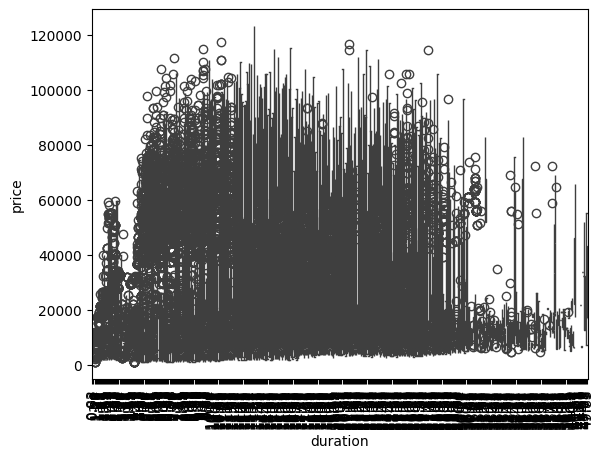

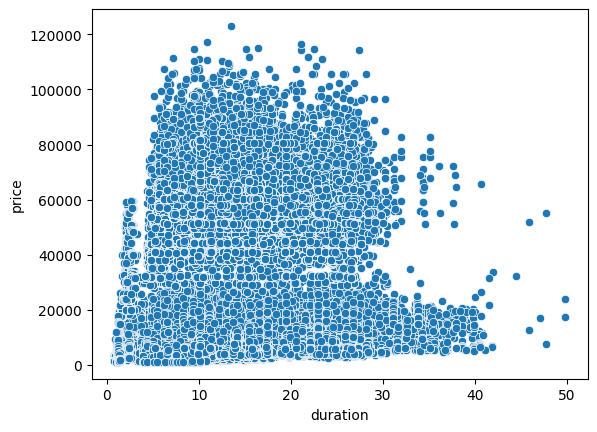

In [ ]:
sns.boxplot(x='duration', y='price',data=df)
plt.xticks(rotation=90)
plt.show()

sns.scatterplot(x='duration', y='price',data=df)
plt.show()

              index   airline     stops     class  duration  days_left  \
index      1.000000  0.179822 -0.123422 -0.802099  0.159007   0.014638   
airline    0.179822  1.000000 -0.029838 -0.178862 -0.001651  -0.010678   
stops     -0.123422 -0.029838  1.000000  0.100262 -0.473860  -0.007047   
class     -0.802099 -0.178862  0.100262  1.000000 -0.138710   0.013039   
duration   0.159007 -0.001651 -0.473860 -0.138710  1.000000  -0.039157   
days_left  0.014638 -0.010678 -0.007047  0.013039 -0.039157   1.000000   
price      0.761177  0.243358 -0.202620 -0.937860  0.204222  -0.091949   

              price  
index      0.761177  
airline    0.243358  
stops     -0.202620  
class     -0.937860  
duration   0.204222  
days_left -0.091949  
price      1.000000  


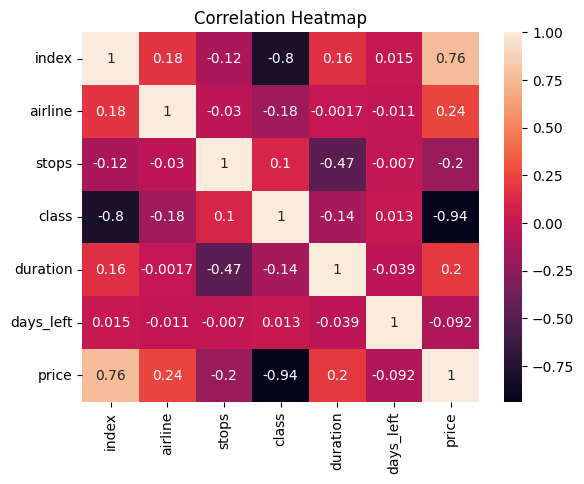

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("airlines_flights_data.csv")

# Encode categorical variables
df["airline"] = df["airline"].astype("category").cat.codes
df["class"] = df["class"].astype("category").cat.codes
df["stops"] = df["stops"].astype("category").cat.codes

# Select numerical columns
data = df.select_dtypes(include="number")

# Correlation
corr = data.corr()

print(corr)

# Heatmap
sns.heatmap(corr, annot=True)
plt.title("Correlation Heatmap")
plt.show()

# Feature 1: Price per day left
df["price_per_day"] = df["price"] / (df["days_left"] + 1)

# Feature 2: Duration Category
df["long_flight"]=df["duration"] > df["duration"].mean()